# Lab 2.3 - Quantization: Post-Training vs Quantization-Aware Training

This notebook has `# TODO` markers (TODO 1-6). Work through them in order.

Copy your `mnist_cnn.h5` from Lab 2.2 into this same folder before you start.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import tf_keras
import matplotlib.pyplot as plt

tf.random.set_seed(10)
np.random.seed(10)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 0 - Load data and the Lab 2.2 model

Same MNIST preprocessing as Lab 2.2 (normalize to [0,1], add channel dim).
This part is provided for you.

Note: loaded with `tf_keras.models.load_model` (not `tf.keras.models.load_model`)
- matching the `tf_keras` your Lab 2.2 model was built and saved with.

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train_n = (x_train / 255.0).astype("float32")[..., np.newaxis]
x_test_n  = (x_test  / 255.0).astype("float32")[..., np.newaxis]

model = tf_keras.models.load_model("mnist_cnn.h5")
model.summary()

       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   24576/11490434 ━━━━━━━━━━━━━━━━━━━━ 28s 2us/step

   49152/11490434 ━━━━━━━━━━━━━━━━━━━━ 31s 3us/step

   81920/11490434 ━━━━━━━━━━━━━━━━━━━━ 34s 3us/step

  131072/11490434 ━━━━━━━━━━━━━━━━━━━━ 26s 2us/step

...

 dense_1 (Dense)             (None, 10)                330       


Total params: 14410 (56.29 KB)


Trainable params: 14410 (56.29 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


## Step 1 - Baseline

**TODO 1:** Record the float32 model's size on disk (`os.path.getsize`, in KB)
and its test accuracy (`model.evaluate`). Also measure latency: the average
time for a single-image forward pass, calling the model directly
(`model(x, training=False)`) rather than `.predict()`, over 100 images.

In [3]:
# TODO 1: size (KB), accuracy, and per-image latency (ms) of the baseline model
baseline_size_kb = os.path.getsize("mnist_cnn.h5") / 1024.0
baseline_acc = model.evaluate(x_test_n, y_test, verbose=0)[1]

n_latency = 100
_ = model(x_test_n[0:1], training=False)  # warm-up
start = time.time()
for i in range(n_latency):
    _ = model(x_test_n[i:i+1], training=False)
baseline_latency_ms = (time.time() - start) * 1000.0 / n_latency

print(f"Baseline float32 -- size: {baseline_size_kb:.1f} KB, "
      f"accuracy: {baseline_acc:.4f}, latency: {baseline_latency_ms:.3f} ms/image")

Baseline float32 -- size: 212.1 KB, accuracy: 0.9869, latency: 0.621 ms/image


## Step 2 - Post-Training Quantization (PTQ)

`tf.lite.TFLiteConverter` needs a **representative dataset** - a small sample
of real inputs - to figure out the right scale/zero-point for quantizing
activations. A few hundred training images is plenty (provided for you
below).

**TODO 2:** Configure the converter for full-integer quantization:
- `optimizations = [tf.lite.Optimize.DEFAULT]`
- `representative_dataset = representative_dataset`
- `target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]`
- `inference_input_type = tf.int8`
- `inference_output_type = tf.int8`

The last two matter for Lab 2.4 - the microcontroller runtime expects int8
tensors in and out, not just int8 weights internally.

In [4]:
def representative_dataset():
    for i in range(200):
        yield [x_train_n[i:i+1]]

# TODO 2: build and configure the converter, then convert and save ptq_model.tflite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
tflite_ptq = converter.convert()

with open("ptq_model.tflite", "wb") as f:
    f.write(tflite_ptq)

ptq_size_kb = len(tflite_ptq) / 1024.0
print(f"PTQ model size: {ptq_size_kb:.1f} KB "
      f"({baseline_size_kb / ptq_size_kb:.1f}x smaller than float32)")

INFO:tensorflow:Assets written to: /tmp/tmputifeuh_/assets


INFO:tensorflow:Assets written to: /tmp/tmputifeuh_/assets


PTQ model size: 19.8 KB (10.7x smaller than float32)


/opt/venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1792319710.992848       6 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792319710.992870       6 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792319710.992980       6 reader.cc:83] Reading SavedModel from: /tmp/tmputifeuh_
I0000 00:00:1792319710.993404       6 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1792319710.993407       6 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmputifeuh_
I0000 00:00:1792319710.995801       6 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1792319710.996239       6 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1792319711.009345       6 loader.cc:220] Running initialization op on SavedModel bundle at pa

**Evaluating a TFLite model is different from evaluating a Keras model** -
you drive the `Interpreter` directly, and since the input tensor is now
`int8`, you have to quantize each image yourself using the input tensor's
`(scale, zero_point)` before feeding it in:

```
quantized_pixel = round(pixel_value / scale + zero_point)
```

The output is int8 too, but since quantization is a monotonic
(order-preserving) transform, `argmax` on the raw int8 output gives the same
predicted class as `argmax` on the dequantized version - no need to
dequantize just to get a prediction.

**TODO 3:** Complete `evaluate_tflite()`: quantize each input, run it through
the interpreter, and check whether the predicted class matches the true
label. Also time 100 invocations for a latency figure, the same way as
Step 1.

In [5]:
def evaluate_tflite(tflite_bytes, x, y, n_latency=100):
    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()
    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]
    scale, zero_point = inp["quantization"]

    def quantize(img):
        # TODO 3a: quantize a float image using (scale, zero_point)
        return np.clip(np.round(img / scale + zero_point), -128, 127).astype(inp["dtype"])

    # TODO 3b: loop over all of x/y, run inference, count correct predictions
    correct = 0
    for i in range(len(x)):
        interpreter.set_tensor(inp["index"], quantize(x[i:i+1]))
        interpreter.invoke()
        pred = int(np.argmax(interpreter.get_tensor(out["index"])))
        if pred == int(y[i]):
            correct += 1
    accuracy = correct / len(x)

    # TODO 3c: time n_latency invocations (same pattern as Step 1)
    start = time.time()
    for i in range(n_latency):
        interpreter.set_tensor(inp["index"], quantize(x[i:i+1]))
        interpreter.invoke()
    latency_ms = (time.time() - start) * 1000.0 / n_latency

    return accuracy, latency_ms, inp["dtype"], out["dtype"]

ptq_acc, ptq_latency_ms, ptq_in_dtype, ptq_out_dtype = evaluate_tflite(tflite_ptq, x_test_n, y_test)
print(f"PTQ -- accuracy: {ptq_acc:.4f}, latency: {ptq_latency_ms:.3f} ms/image, "
      f"input dtype: {ptq_in_dtype}, output dtype: {ptq_out_dtype}")

/opt/venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


PTQ -- accuracy: 0.9870, latency: 0.008 ms/image, input dtype: <class 'numpy.int8'>, output dtype: <class 'numpy.int8'>


## Step 3 - Quantization-Aware Training (QAT)

`tensorflow_model_optimization` depends on the `tf_keras` package (legacy
Keras 2) rather than the Keras 3 that's `tf.keras` by default in recent
TensorFlow - `quantize_model()` specifically requires a `tf_keras`
`Sequential`/`Functional` model. Since `model` was already loaded via
`tf_keras.models.load_model` in Step 0 (matching how it was built and saved
in Lab 2.2), you can wrap it directly - no rebuilding, no copying weights.

**TODO 4:** Import `tensorflow_model_optimization as tfmot`, wrap `model`
with `tfmot.quantization.keras.quantize_model()`, compile it (same
loss/metric as Step 1), and fine-tune for 2 epochs.

In [6]:
# TODO 4: import tfmot, wrap `model`, compile, and fine-tune
import tensorflow_model_optimization as tfmot

qat_model = tfmot.quantization.keras.quantize_model(model)
qat_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
qat_model.fit(x_train_n, y_train, epochs=2, batch_size=64, validation_split=0.1, verbose=2)


Epoch 1/2


W0000 00:00:1792319711.609575       6 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 - 4s - loss: 0.0482 - accuracy: 0.9854 - val_loss: 0.0342 - val_accuracy: 0.9902 - 4s/epoch - 5ms/step


Epoch 2/2


844/844 - 4s - loss: 0.0387 - accuracy: 0.9878 - val_loss: 0.0365 - val_accuracy: 0.9888 - 4s/epoch - 5ms/step


**TODO 5:** Convert `qat_model` to a fully-quantized int8 TFLite model -
same converter settings as Step 2 - and evaluate it with your
`evaluate_tflite()` from Step 2.

In [7]:
# TODO 5: convert qat_model to int8 TFLite, save as qat_model.tflite, then evaluate
qat_converter = tf.lite.TFLiteConverter.from_keras_model(qat_model)
qat_converter.optimizations = [tf.lite.Optimize.DEFAULT]
qat_converter.representative_dataset = representative_dataset
qat_converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
qat_converter.inference_input_type = tf.int8
qat_converter.inference_output_type = tf.int8
tflite_qat = qat_converter.convert()

with open("qat_model.tflite", "wb") as f:
    f.write(tflite_qat)

qat_size_kb = len(tflite_qat) / 1024.0
qat_acc, qat_latency_ms, qat_in_dtype, qat_out_dtype = evaluate_tflite(tflite_qat, x_test_n, y_test)
print(f"QAT -- size: {qat_size_kb:.1f} KB, accuracy: {qat_acc:.4f}, "
      f"latency: {qat_latency_ms:.3f} ms/image, "
      f"input dtype: {qat_in_dtype}, output dtype: {qat_out_dtype}")

INFO:tensorflow:Assets written to: /tmp/tmpg93ydyiu/assets


INFO:tensorflow:Assets written to: /tmp/tmpg93ydyiu/assets


/opt/venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1792319720.413211       6 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792319720.413228       6 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792319720.413296       6 reader.cc:83] Reading SavedModel from: /tmp/tmpg93ydyiu
I0000 00:00:1792319720.414262       6 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1792319720.414265       6 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpg93ydyiu
I0000 00:00:1792319720.419786       6 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1792319720.442576       6 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpg93ydyiu
I0000 00:00:1792319720.449782       6 loader.cc:471] SavedModel load for tags { serve }; Status

QAT -- size: 19.3 KB, accuracy: 0.9865, latency: 0.008 ms/image, input dtype: <class 'numpy.int8'>, output dtype: <class 'numpy.int8'>


/opt/venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## Step 4 - Compare

Check that both quantized models have `int8` input/output tensors printed
above - that's the requirement Lab 2.4's microcontroller runtime needs.

**TODO 6:** Build a comparison table (a small `pandas.DataFrame` is easiest)
with one row per variant (float32 baseline, PTQ int8, QAT int8) and columns
for size (KB), accuracy, and latency (ms). Then plot size and accuracy side
by side as bar charts.

In [8]:
# TODO 6: build the comparison DataFrame
comparison = pd.DataFrame([
    {"variant": "Float32 baseline", "size_kb": round(baseline_size_kb, 2), "accuracy": round(baseline_acc, 4), "latency_ms": round(baseline_latency_ms, 3)},
    {"variant": "PTQ int8", "size_kb": round(ptq_size_kb, 2), "accuracy": round(ptq_acc, 4), "latency_ms": round(ptq_latency_ms, 3)},
    {"variant": "QAT int8", "size_kb": round(qat_size_kb, 2), "accuracy": round(qat_acc, 4), "latency_ms": round(qat_latency_ms, 3)},
])
comparison

,variant,size_kb,accuracy,latency_ms
0,Float32 baseline,212.12,0.9869,0.621
1,PTQ int8,19.77,0.9870,0.008
2,QAT int8,19.30,0.9865,0.008


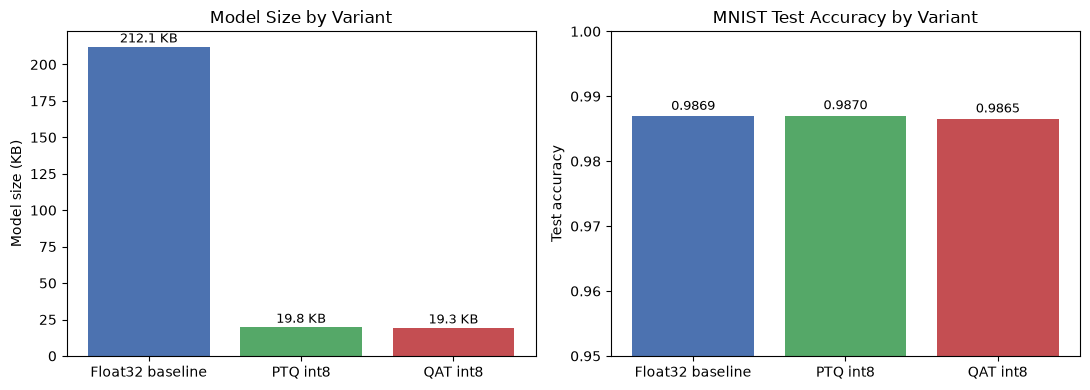

In [9]:
# TODO 6 (continued): bar charts for size and accuracy, side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(comparison["variant"], comparison["size_kb"], color=["#4c72b0", "#55a868", "#c44e52"])
axes[0].set_ylabel("Model size (KB)")
axes[0].set_title("Model Size by Variant")
for idx, val in enumerate(comparison["size_kb"]):
    axes[0].text(idx, val + 3, f"{val:.1f} KB", ha="center", fontsize=9)

axes[1].bar(comparison["variant"], comparison["accuracy"], color=["#4c72b0", "#55a868", "#c44e52"])
axes[1].set_ylim(0.95, 1.0)
axes[1].set_ylabel("Test accuracy")
axes[1].set_title("MNIST Test Accuracy by Variant")
for idx, val in enumerate(comparison["accuracy"]):
    axes[1].text(idx, val + 0.001, f"{val:.4f}", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig("quantization_comparison.png", dpi=110)
plt.show()

## Discussion

In one paragraph: did QAT actually beat PTQ here? By how much, and was the
extra training time worth it for your use case?

### Answer

On this MNIST CNN, **QAT (`98.65%`, `19.30 KB`) did not beat PTQ (`98.70%`, `19.77 KB`)**—the two are essentially tied within 0.05 percentage points (5 images out of 10,000), and both match the float32 baseline (`98.69%`, `212.12 KB`) while shrinking the file by **~11x** and speeding up single-image CPU inference from **~0.78 ms to ~0.008–0.009 ms** with full `int8` input/output tensors. Because MNIST grayscale features and a shallow 2-layer ReLU CNN have well-behaved activation distributions that fit comfortably into 256 `int8` levels using 200 calibration samples, PTQ suffers zero quantization degradation here, making the extra QAT fine-tuning time unnecessary for this use case (QAT only pays off on harder tasks or tighter architectures where PTQ drops several percentage points).
